# ETTh1 Transformer Temperature — CatBoost vs MLP vs sequential models

**One forecasting task, one dataset, one reproducible pipeline.** Run all cells and share the executed notebook plus `forecast_challenge_outputs/etth1/comparison.csv`.

An independent **test** partition follows chronological train/validation partitions. Hyperparameters and possible feature augmentations are configured *before test*. Models use the same target windows, last-observation-relative target, and known-in-advance calendar inputs. The 300-tree CatBoost run is a new execution, not the earlier unverified note.

**IMPORTANT:** Model training budgets are fixed rather than exhaustively tuned; this comparison does not establish a universally best architecture.

## Protocol and sources

- **CO₂:** Mauna Loa weekly CO₂ (1958–2001) via an embedded copy of `statsmodels.datasets.co2`, 13-week forecast from 156 weeks of history. Same source as the earlier notebook. Missing readings are forward-filled (causally).
- **ETTh1:** Official [`ETDataset`](https://github.com/zhouhaoyi/ETDataset), 24-hour oil-temperature forecast from 168 hours of history; six other sensors are past-only inputs.
- **Jena Climate:** [Keras / Max Planck Institute for Biogeochemistry](https://github.com/keras-team/keras-io/blob/master/examples/timeseries/md/timeseries_weather_forecasting.md), hourly resample of 10-minute weather readings. Predict 24 hours of temperature from 168 hours of past weather. **No future measured weather** is used; invalid negative wind speeds are treated as missing, and wind direction is encoded cyclically.

All data are chronological 70%/15%/15% with forecast targets fully inside each partition. Scaling fits on train only. Metrics are in physical units. The CatBoost engineered ablation gets additional past-only statistics not given to neural models by default; interpret as a pipeline comparison. Original electricity/Beijing notebooks are included separately as references, not merged into this experiment protocol.

In [1]:
# Run once if required: %pip install -U numpy pandas matplotlib torch catboost nbformat
import base64, gzip, io, os, random, math, json, copy, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset as TorchDataset
from IPython.display import display

# SET BY THIS NOTEBOOK — reruns are reproducible using the same settings.
DATASET = "etth1"  # "co2", "etth1", or "jena"
SEED = 42
MAX_EPOCHS = 30
PATIENCE = 7
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
CATBOOST_ITERATIONS = 300
CATBOOST_PATIENCE = 50
RUN_RAW_CATBOOST = False    # optional raw-level target ablation, not the primary comparator
RUN_ENGINEERED_CATBOOST = True
NEURAL_ENGINEERED_FEATURES = False  # train a separate variant only if intentionally studying feature engineering
# By default all the core architectures, including a patch-based Transformer, run.
# Full attention over all 168 hourly steps is expensive on CPU; enable RUN_ALL_MODELS for that ablation.
ALL_MODELS = ["Linear", "MLP", "CNN1D", "GRU", "LSTM", "TCN", "N-BEATS-style", "Patch Transformer", "Transformer"]
RUN_ALL_MODELS = False
MODELS = ALL_MODELS if RUN_ALL_MODELS else ALL_MODELS[:-1]
# Limit evenly spaced forecast origins in large datasets. SAME origins for every model.
# This is an explicit computational trade-off, not a test-data-based filter.
MAX_TRAIN_ORIGINS = 8000
MAX_VAL_ORIGINS = 1600
MAX_TEST_ORIGINS = 1600
DEVICE = torch.device("cuda" if torch.cuda.is_available() else (
    "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available() else "cpu"))
torch.set_num_threads(min(os.cpu_count() or 1, 4))
np.random.seed(SEED);random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
print("Dataset:",DATASET,"| Device:",DEVICE,"| PyTorch:",torch.__version__)


Dataset: etth1 | Device: mps | PyTorch: 2.12.0


### Embedded CO₂ series

The cell below only contains a gzip+base64 CSV copied from `statsmodels.datasets.co2.load_pandas()` (date / co2); it exists to make the notebook self-contained. No synthetic data are used. Change `DATASET = "etth1"` above to exercise the standard forecasting benchmark.

In [2]:
CO2_GZIP_BASE64 = "H4sIAAAAAAAC/12dS651Oa6c+x7LrYulJ8XhGLbb7nj+8L/FiCB1gGpsROotPrS+w8z63//z//2f//pf/7f/j+br/Ocb/+n+X6Pt/24Q5n++9U+w/x4SWr/CTsGvsCT0fceYENa/ca/gEtr3X/nbnu7rP31eIVuPxtb7P5/l7zbzdy9t+uFvi+Wv/z4S7vIfwa8wJdzlLy3o3/+iy04hujQJLbp8Evr4L/0e379/ONXa/y3xnzA0gf+nqbX/p3/lNzfbvn/nmr9bK79P/u6Lv9t/vlZ+nzvhJ6GtK3QJvdcl/QS/i2aXHoueatF/i/4JU0KPfVoKdk/lzvJv1y3soArty6MOwfKor3CNAdd1hX/GoOv6J3RaxP3dZhraFXq7wk7hPML4df8JRwKs6v5Gd0vhPML8XcvPWFNo7QothZP+coX+O/wTHuXXPfoVegp+BZNw7evEbVyhjytMCePjqndc1dGp7riqozXtuCrTpndcVW7DYl95LBb7eoSTXn6Fu6+tWc7PBOtlnrDDqes5PzvU797Th0Lw9Bu/frPS4q7Qwmo9BU8zvkLfVfi50UhXuMI1wcFZfoJdYUq4JliFa4Ja2M+/rC7s51/zCkdCb9Xyf8LJEOLXv1bd/s+/ej29n+DVFX7+FVHnd2n7u/7V/wquOwqhbdlvCD1C85Jwo1U4yE+A41ehZTQPAdY0Uwhr+iCM2Fx2GUwiloLLwkO4m8sWk16yU/h18etHIdzNucaYsbkq3M25Bl1xc66Frbg5v4ccwu/m+qcx1r25IuxwFdf293WVp8V1ldriukouzLi5loI/uzWGgCnhbs60dIvNmc7j/L25w5szCf2TFUIwxfCf4OEvVWif8gCE6NIlwF+wjp/PtSvsFM6fFshHLuEGAw36E/wRGoPBkgB/aSn4HwH+giP8+dyQR4XQwvi/FCI7dAl9Vo/6J4zMMLtdn7M85Cu0md5whd7+CucROrNKCsgqlsLJ278Csgq7jBijCneMSAsQzhVcAsbgLDNuDoYbQljyktDWM8aMm/MyRg835QGta5b/3COFn1n+E6aEn1k+LX5m+U8YEPa9ObrYFdr3V7Bn2h03l3sxbq6ncNIrr4DNZZfeldwh+HMNh8/lFBDpRgr+2MehWXIdzjBeBFfeDKHlYyyEPpQ9Qhifssdu1+esjvHzuZnecIXe/gon00m7PpePsRBa+9MCj4IuAY8CrPTnc/2v4NXWfz63M1lcAZGuSRgl4fTrcztP/QrlxRPCjXTwhhDyxfMTEAyyBYJBvNMgWNr6FWBSbDFiDJjUFdqXRhdCSThXwBgmYUT24Bjz3twj/G6uN610MkdZCif9pV+fW1c4En5mWbqsa5Zl0HXN8p/AI9z35v518RT8GXTfm/snLAk93DTHGN+zF+PmmgQkYJfQW3plCCejVL8+NzNXXgHRsqdwHoM5+FL6/XZ8KeH3yd9tZWS/Qi/PqxAiw2CtPyfbmXKu0Eb61BWQcS0FewR9JLkEJKWZgqWDXKGXdNGvT+VHCISTUegKbemrJITeq8f8BL9HMa5/rUwdV2g97yAET9+4Qo/3yoHQ+cSxFN4u1/H1G0+3AWFE90fwdJwr4Pl3JMD6sku1vnFdaz8tJlORS7ipqMfRhmDXLdhi4cM8ft+XX/2HP8P7171L+MXDIux7Vf+EkcJ5Ztz3qv4NeiT0nn4XgmcCHderdnrVFdp4zsbCDl03amGHrmkP4+GWgHjYUygh9AqwwyYBjyMuzOvXdgjIQi4Bn9xfCqe2+DnZyhxzhfKlBCEhVgggUjjk1piFdgpeF9bwpaS9tAakE7+RgHB6rce+DlfdQCJ0WA0k4pQuNYzN62Qzb+AKrby+Qjh5i1dAGJvXnVr5ffJ3K23+WU7+dv4eYCjxO/hH/O6t/NaYkzY/ATzyd2mTa7uEI397/obHTyAN/R7F6yaRxiM0td5AZvgd7rkgBMhgGpsCGUgwkyCDUWESZPAtOQUyXGOccr6Hj8QtoSfOgeAZWqdAhuliATK2Vu38dkkBn8NYE0HG5jYIMjQGQcamtRBk1DFGyyQwBTKMNtn07ZIt8O2yUjh1cwQZh5sjyDjq0p9cMQUyICyBDLjCEsjADSyBjCogYZgEBHu26AyKXUIbf1rgu8NSsIy06zrKzlfSFWrCuALGmCmERVKY8e3S1GXGt0vXwua9uX9Ck9BnpoB1nSiyxkzhPGMsZg2XcLNGi6sMwZ8uOx6JOcuOR2LTeWw+ElPAI5Gz2N/NWWwuB7XYXI5hsbk8MQuzdAmHlCaFVr5tr4DoelIo0XVdn5v5mr8CPoe/FE767RXw7YJBfz5XskYIng/NKyBrZBd8uywJSB0co5HWDgmtfERcAd8unoJV42/9SR1XQJAbKZw/AhDUPaB9XazlB3MIJ+/lCm3lZ/kVYFJfCp7Bdl+fC5PqEqpJheBplleASR0IAQ/pDZvw8BXCkpeEHumCYwQ87EMtAh72oWkDHv4Tsst9PYJJbcLDMkbAwz61/YCHfWphgIdDuwU8nHENm/CwjAF4mOsIeFjGCHjYh8YIeFh2G/Dwn+ASkGc3uKF+x18Nfr8PQ9uQgNB2JODN2FKwx2Sc378uob4Zt2jhkVGBFh5OS1poHIO0sArIuF1CL2h4ixbmoPcDRr9bz6fvJihkvt8EhcwUm6AwjwKg8BWsWj5AYR4nQCEFIyhkqDSCQl6bARTm78Pf4e50ACMeZCg34kGahBEP/hM2hMExXALGyBYwvCEBhsdZAg/2oXUEHuyztLghI/4yEsINGVOzBB7sS2MADy6NATwIBG3Cg4BdJjw4tRfgwSrc+8ppAw+WzQUepHcb8WA5QmOKTaGtTMJGPPgKns9WIx5ktDPiQb4OjHiQUdeIB2mdRjz4Cp7p0YQHXZvz5w8hJjx4uBfiwSrUP4SY8KBmIR7MFvEBkwsDHuTntREP8rVkxIN8rhvxYJ4H8CDTgREPpq0DD6YfAQ/yk/oQD/JeDvEgE8YhHnwFy8s+xIN0j0M8SOM/xIN9aJZOk2KLwSxUBM9gf8gwHqGP9KgjhgFvOGIYVbibg3scMYypQcEwlla64uaWNgeQkWMAZCwdEEDG0qAAGTkGQMbSwgAycozNYOApeLrpEcjIzRmDQZPQv0zThyCjXMPhzaVQ39uHIINueggy+Eo5BBk0y0OQQTc9BBlMAEcgwzWGP/5yCDKISw9Bxit4JqIjkOHcLUAGP1kOQQYz0yHIyKUHyCibA83I7YNm5ImBZjBZHNIMhs9DmkHTdtIMtnDSDL50nDSDbyEHzdDdOpDGH+HkZTvgRh2j06QOhEGzbCkUS46Cj5V2GkUe/QqegqetO4uiOhCUsyiqm2aJoqi+NUsURRUhiqK6FeGapWmWqIzquwjXLLcWtsIsARIc5VF1lh03t7W5HTf3COcKPELj5pqEu7mtm4uSqXJiUTLFgOIsmepT64iSqUdApGsSeonJzrqp0sIZxrsEhHGTgDB+UihvLEcZlRKOo5ZK+cVRUCVvcFRV1TEaXwY9hZO5wVlflQtDfVXuBfVVfG4466vStFFf9QgI4z0F05nax/oqRMsQ2qd7gWCK6yH0KX8JYTS5h32or+JlhwCT+iTApEYKRxZkH4usYMkhYIwUepM3QDiydftYadXj1R9Ca/IXCOePcG/uaNCotOqmQaPSqkwblVb9aHNRadWPNgc2mWOATeYYUW5V1hHlVt10hKCUpr2AUlahNUUYCOePgAS8IRxGup7C+SMgWh4JJVpCcEVt+4gqEflDaPklDcFl2iH0XQWgSnw3hNC+OgZQZc4CVNkHrwGosgyKr6fB7QNV4js5hN7kLxBOdQ+gykdovboHUGUeIVAl3aMRVdI9GlElkkUIbSudhHBNapcu16SCK1kTqtyaBcEg/pASQv+eMTpN6oMwaJZNAsxySIBZZheMwVkmc1QKyFEtBUvTbkKVR0sHqoTfNqFK17RAlV5aXLM8OjGgyqMzBarMWYAqa4sWXZqEvp8uxs25hJKAIVh6dhOq3FppoMpyDYeRrklo+bQOoYebjhSOHkbWiCpp2o2okv7SiCrpUY2okn7biCpfIZlQCEjASwKA15aATw3cPlAlXlsh4DW+JJRPcwhW/QWoMrcPVJnuAVSZhwxUyfzSiSrpL12osgpt/RF6/yt4RtwuVAlb70KVsI8uVAn76EKV2WUwjC8JyFEthZP+0gVVjhY26S+eQvjLlAB/ORJ+mxufZgmoMuJL3DqhyiPcm3OtI6BKGSOgyvh0QIAq2QVQxdUFUMU1y36CQRdUyd0CqhzdLaBKHpAxGLQU/DnkwwerS2jvZZ/6Gg8BYZwrdYbxmUK+cUNoO3NlJ1RhfumEKikAqmQXQBV6QydUwdcJhJPZowuqyPgJVba6NPrLlNCf8yBUeQSvZkmoYjwxQhUrXe7mEMaHoEqQ3BDa+CP0Ly97CKogSA9BFVjQEFQJNgshTGpLuCYFKxysuerxSRxCK5Y8WHM1Pg0aNVfj0zqi5mp8miVqrkbTbqPmajQNGjVXo2naqLkaXS2i5mp0jRE1VyO4FAS/wpbwM8vRtdKouSpjRM3V06JFl0/C7+ZG06BRczWa7sW4uSUBm/sk9JbhYrDmqpxp1FyVFlFzVW4uaq66a7fneY0PFF5Vg/EIBqalO4PBkdDzOxuCp6sPlmDxUTNYgsUgPViC9QpWB0UJFiPMYAkWvwoGS7DSG1CClZtDCRZj4WAJVj80XJRgpXugBKsM2vnsuV0m67CYGybrsPh0mqzDYrKYrMNispisw6I3TNZh0Rsm6rDkDZPFWEUYHMNS8PSXSZBJb5gEmbTTSZBJK5wEmaNr6QEyyxgBMkfX9gNkjqEWATJLiwCZY2jaAJljaKUBMkfX9gNkljECZJalB8h8hF7cdBJkjqYDCpD5CG08J2ZMwDMFS6+cBJn0uSmQ6VrpYbTsEmCW2WK0zKZTIPNoUIBMfCZMgkxmj0mQmS0IMquAp9OXQsnZkyCTaX4KZBpnIcjUwggyDy+KIPPQLAky5S8Ema5pwS68tOitugdBJlosgUwc8hLIRJdFkMmX0iLIZLJYBJmvcDImL4JMXvYiyKTBLILM0TTt4BhbAsZwCdUsF0Ems8ciyKR7LILMMUqLm6OqcHPU0F4CZI6haQNkvkK4qUm4CbgKNwFPDRogcwztNkDmwAfNIsgcQ0cYILMszJiATQIS8JeCP6ceIJNBaRFkMjgugkyGvkWQOT4tDCDTiwCz5BgAma6lO59OS0IvCWcJZB5eJUGmWhBkPsKpgxJkah0EmVopQaZrlsZPjSah9/SoRZDJl8EiyMzzAMhkwlkEmekNAJmMhZsgk9ewCTJfwdI9NkEm3WMTZNL4N0Em08kmyKQ3bIJM5oZNkMmUtAlVmCw2ocrAR/MmVKEVbkKVgY/mTagyppYeUGVMTRtQZUxNG1BlTK00oEoZI6BKmSWgyphaWECVsTRoQJUxtZeAKmWMgCpljIAqT4t+C0tsk6eUozDGgZmCPacXPKWcr/HSeHqHb1WT0Ga+RTZ5yiucTJNbPMU1RvCUp0V9q27xlMOFkaccLp08xTkGeYpzHeQpzr2Qp2SXxjhwJMBVpgQ8ClYKluFnk6fQmTZ5ymjcC3gK08ImT6FnGHkKHcHIU3gvRp5CqzbyFLqKkacUoTO1TAlILSMF/9MCqWVDGLTIJqFapLH0a6zS4o6BL3tj6ddY2lyUfg0AJ2Pp19ily32rbg0apV8DmM9Y+jXw9wtj6dfY2kuUfj0trlnmGFH6VbpE6dfYOqAo/SrriNKvslL7uznj5pqEtv8IfTxHGP/eKJOxsRKMjwJjJRhfxMZKMDqysRKsCFEJRkc2VoIxxhsrwZ4W+CrHLKgEozcYK8GeFnjxLAl4NRWhPMSN/95oTotyMD4KjOVg6Q0oB8vNoRwsbR3lYHwkGcvB+HwxloMxxhvLwXgNh+VgbHFYDva0uCaFCH74743Skg8Lw2j8h4VhvP3DwrCxNCiCATjXIcMcW+sYNMuWwknTPmSYA+//Q4Y5TOsIhjlMKw2G+Qj35kybA8M8GgMMswrXLI8WBoZpWhgYZs4SDHMczRIMcxztNhhmGSMYZtmccXM7heLZhwzzEZB7PQV/riEYZrmow0h3UvB8FBwyTCbjQ4ZJoztkmDTcQ4ZJ4z9kmERShwyTb+ZDhpldwDCZGw4ZJsPFIcNksjhkmHSPQ4aZKwXDfIS+qjeAYfIJdMgw84DAMPMIwTAf4W4Of3twMsxHaCMvyskwaetOhjm2WiAYVKFFl5WCpTk4GWYRgmEOECgXw7TSAmY5Jdwx8JhwMcyjlYJhHg0KhonvZRfDxHPfxTBdLcAwXQcEhpmzgGF6Ea5Z5hhgmK4DAsN0HRAY5ikt+vgj3JvL3Ro31yW0mX7rYpimpRsTMFuAYZoGPYx0K4WSgJ0Mk1boZJj0SifDHFODOh/iXUJ9OjkZJl85Tob5CK18YjsZJnO2k2GWLu35ynAyTPqLk2Hy7eBkmAxKToaZ3gCGmQcEhpmWDIaZhwyGCcM9HxkmwmcIrf9p0SLyDwl9K2qfTwwzUgEEl62HAJPaEmBSHQJ4imsW8JQwyxB+m5ufZgmeMr/S4re52dQieMr8tNLgKTOeLBD8Cibht7kyRvCU2TRL8JTZtNLgKY/wu7kyS/CU2TRL8JTSJXjKI/z8ZQbpgHCevdjfzYGnuGYx3tyS0NOzzyeeYlVwRboQ7s1VoY8/wvjkt+cjTxlbl+0M4yahR+TvKZhe0ucjTxmL2wdPeYUMBiHgNY7zAE/JdYCnIDeEgGdPk4Bnz0jh8RfyFG2fPEW2Tp4ifyFPCQ56mngKrqGJp8S3KQRLb2jiKVUYLd2jkafQGxp5Cv2lkafMAKMQzjU6Tjs4hkmAWX4SeljySeE3RtcYURg240ESwu/mXiG6mITfzc2uzUVh2Ow6oCgMm0PriMKw2bWOKAwrg0ZhWBGiMGzGn/dCaNFlSejfs7koDJtNXaIwrJxHFIbRTRsLw+iEjYVh5dQPI91K4TzmEIVhDLCNhWHDSpde3LSxMGyYZnGG8S8FV24IAZ/mmBaFYfjgDQFPp52Cpb80FobltCgMy5WiMAwPgRDw7GkSesso1VgYlraOwjA8jEJApJspuF45IdwwjlPvLAx7hYj8Q0LbafydhWF0j87CsNk0RgSDGSwnhPZ26TSpIlj6SyfDpFl2MsxH6MWSOxkmjb+TYdJfOhnmHNpcMMwZb/4Qbo6a2kswzDk0aDDMObSOYJhPl5uAp/YSDLMIwTBnMKUQbgLOdQTDfFr0/ezFuLklocV5fCnYH6HPdOROkMn02gkyGS07QSajZRfIdJ06QObRGAEy8fgOobV85XSCTBp/J8hkBuoEmUw4nSCTb6lOkMkHWifIZM7uBJnML50gk/GjC2Q6b44g00uXbvpuOF0gswqIdDOFU/0FIJOxcBBk8h00CDJn/J0thGtSeFwNgky62CDI5NNpEGTysgdBJt1jEGTSYAZBJv1lEGQy4QyCzNIlQOacmiVAJt1jEGSWFgEy5ywtbkBZpcUNKEvTBsicS+cRIPMRrlkubS5A5lyaJUBmaREgc8Z3Qwit/RXOs7AAmXPqooybsxRic0tCi/PIFndzQ7MYEzCFAJlM4oMgs9ztYaRrKVg68hDIdK3U+XQqQrHkIZCpFgSZakGQ6VwHQOb8uA6ATGaPQZDJ7DEIMtP4ATL5VBgEmUwFgyAztw+QmbsFyEzDBchkXB8EmXnqAJmMp5Mgkxc1CTKfFr1lTJ4EmQzjkyBzBtsK4ZrUVBcEg9oCJrUhBFShe0xCFRrdJFSh8U9CFRruBFTB74n/SEr8jv9ISvzupc3diGnEACiPcG/JdDoBUKZpIwFQJh5SkwDlFfyPcH1ja6sBUObWoAFQZlDdMwlQ6NaTAKUchtHxswtuiS0Ob+mTgFtqKURKT6GXYDoJUPjinQQo8ysCQvaQgJBdBE9XmAQotPxJgJJdAFD4kJoEKLkOAJRcKQAKw8skQMnNAaCk5QOg0FkmAcocmrY/T5xJgJKGDoBCYRGgMFQuAhRG10WA8gh9P0IAlImn+CJAmUuzdOaSI6Ga1GIR2Nxax6BZNgktLHlJuGNY6XLNElRmsQhsHq00isAeoUeXlYJdgSuNIrBHuGbpWnoUgU3XSqMIbB4JUQQ2XdNGEdjEE2exCKwsPYrApulMowiMvr9YBDa3WkQRGP12sQhs7tKlWybbhSIw/UZAy394LTJt5fDRPSQgWrNL1H/RABfrvxjxF+u/+Dm9WP/FpLlY/5UtUP/F181i/RddZbH+aw5Oi/qvnBb1X7lS1H/lSlH/xYi/WP/F585i/dcjtBLgF+u/5tLCgChg5pv1X7ySzfqvCXS0Wf/F2LpZ/1W6IA5kC8QBXPxm/Rd9Z7P+a5q6BK9k0N/klRMfy1u8sna5Y7gGBa88mha80tUFvNK1dPBK13kEr1yfuoBX4rmzySvXp2mDVz5dfmb5tPiZZRHAK/FC2uKVgBhbvDJXCl55tA7wyqMDsif3bvLKaaUFci8HPQxyOwV/rvIwUC4JeHRnF5gluwSvZDje5JW0001eyVS7ySvp2Zu8kplkk1cy927yyqcFXkgcA59LS13wuaR1gFfmXsArGY82eWXaOnglg9wmr2Se2OSVT4u7OZi2kVfyXoy8cuJT2MgrGX2NvJLR18grmThMvDJbIBjkGAgGSC0mXgkbM/FKOJCJV7rGGDRLS+Gk8Rt55fo0RvDKp8Xv5haeL0ZeuZq2H7xyNS0seOXq2m3wytW0juCVq2n7wStLi+CVq+nUg1eWdQSvXE2zBK9cnwYFr8ztG3PvSeE8Rwhe6Tr18+ReI69kdjbySnq2kVeWyz40S67D+RD/JLTi2UZeSc828ko+gYy8ksZv5JVMFkZeOTf3Al7JQG/klTR+I6/k+9/IK9P4wStz++CV82gd/Yl0Rl6ZhwxeyVRg4pUw3CNeiZs75JU0y0Ne+QjXpL7SBSbFFp0mdSTApIYEmNRKwa4lUwh2srrGCHZSBg12Qks+ZCerax3BThbeH4fsZA3NEuzkaXE3h4+bQ3aypgYNdrKGpg12sqY2F+xkTc0S7KSMEexkTU0b7ORpcYMBviEO2UlZqXFzXwr+HGGwk9U1hj3B4JCd0NUP2Qk9+5CdrE+bC3aywOeO2IlrFufLYEhAGLcULHP2ITuhrR+yE1ryITt5hBoMjtiJc2FkJ7J1shPZOtmJa9D4hOKD5JCd5G7BTtbHQwY7YXA8ZCeMp4fsJI0f7GTh4exkJwto0clOFuC0k53wbp3shLfvZCf0Fyc74e072cnC49vJTtbQOqIIjDbmLAJ7WmCMJeGOMdUiisBo/M4isLW00igCW6t0+d3c2qXF7+bW0vajCGzhheIsAltLu40isLW02ygCW0tnGkVgpUsUgZWFRRHYmqVFDzflOuzv5qIIbE3NEkVga2iMKAIrZxpFYOUaDiPdlnAjXS8tEOmahGqWziIwxmRnERijtrMIjO7hLAKjmzqLwOgeziIwPvGdRWBPi97qLCgCy4WhCGx93ByKwJgsnEVg9BdnERhfOc4iML5ynEVgq/M8UASWHoUisPQXFIHBkv1jEdgjXJMK0w6hf7pKCBH5HQKCQYTxEIpJQUiTCgEmZRAGzTKF9snoIJgMN4Q7xtK0UQQGf/GPRWBrq0UUgT0t7s3FOwjCeboEw1zxQgnhmqVpc8Ew19agwTCXaYxgmKVLMMwybTBM+G0IPc5jSRjfc0DBMEsLYwL+JJQEDOE8p34Y6ZYERLqewlEIDqEvWaF/ZJjIlRCOnDCElg/4EHr/06V7FcAw4eoh4On0ScDTaaZgjxDfUXCPEK5JdR4yGCayRwg9I79/ZJh4f0A49ZDBMNM9wDDz1MEwafyNDBOvnBBaz3tpZJhPl77ToxoZ5loaA8GgCtek4ts0hJ6R3xsZZmkRDHOZxgiGueI1HsIdA7beyDCXSQiGueJjNYR7c6Zpg2GueI1DsCtw2mCYpUUwzHU0SzDM/ek8gmEulxAMc8XnLIRzhSnh3tzRtMEw19G0wTCX6V6CYZYDCoa5tmYxJuBsgQTM8ziMlkcCIt1OIZ/WIcAsPwmjuGkjyCwtnE+nJqE3fTdAyITjjSATHxIhIAG3FPJpHQI+Ndil8TU+U/C6F4BMhpxGkEkHagSZ+JDwRpBJj2oEmcwNjSAzTx0gk8GxE2QywHaCTLy2IJTI3wkymSw6QWbpgmAQ39khtJIsOkEm/aXj/3hABtMJVUqXgCr0l06oQrPsgiqw5C6ocjTofPylC6q4VjrpLx0CoIrrgABVsgugyikt7s3VLr+b258GDahCN+2CKq6lA6oczQKokpszbi6FuznTLMabGxLu5vIqDx+snsJJr+yEKo9Qw3gnVKFZdkIVWnInVGGy6IQqq5cu1V86oUp2AVRZg10AVejqnVAlpwVUKUJjMHAJbaaLdUKV3BygCmNQJ1RhlOqEKnlAgCr4fgkBOepOOwhVVjAlCOWlNARV4EBDUAUPoyGogqfTEFTJFp35pUvoX3rUEFQxdRlPjhosAqMDDRaB0ecGi8BWfHj7YBEYc9RgEdjTolna+mARGL1hsAiMDjRYBEafGywC218Rfma5v9LlZ5b7016iCKyMEUVgy3XqUQS2vHS5N5d7iSIwZvXBIrB1tPQoAisHFEVg5V6iCIyRbrAIjO+PwSKwYjCHZlmE8mAdLAKjEw4WgdE9BovAaOuDRWApoAjsFfyPcM1ycrcoAsPnfQg1Rw0WgeVKUQTGr5PBIjBmoMEiMKaTwSKw9BcUgeURoggsHQhFYCv+yOyTRWC8l8kisEfAs2dKwLNnpOAZkyeLwEoXBAOkgskiMD6/JovAaNpTIDMHHTTLk0JY8pTQI3uwRYBMGv8kyNxN0wbIfITfze2mzQXI3EEVfBJk7qZBA2TupnUEyNxNSw+QuQMg+iTILNMGyHyFeLBml148exJkMnlOgUxXF4BM18KMCfiTMEoMmgKZefuH0XJJQLTcKVhm00mQyc+ESZD5CpapYBJk8vk1CTKzBUAmg8EkyKQ3TILMXAdAJiPMJMikN0yCzGWaBd9RVlr05zwIMmXaBJleWrTydTIFMmuLEWH87nYJZML4F0Em73YRZO4grBDKB80iyKStL4JMmtQiyKR7LIJM2voiyKStL4LM3apQzHIRZO6uWQJk7qFZAmRuPPEXQeYemjZA5u6ly81RQwcUIHMPrSNA5p46jwCZr2DPtAEy99DSA2Q+LX43t3tp0eezsACZu2thATLLiQXIpKsvgszdShckYLYIkMk4tgQyXYMCZCIWLoHMbOEkRiMFzxfKIsh8hD7yc3YRZNLVF0EmXX0RZD4CPjW+FE4dlCDTeS8Emc7dEmTK+AkynacOkJnGD5CZJwaQuT8tPdhF2jpAJmPyJsjc+L7dBJm05E2QufE5uwkyedmbIHMDEG2CzD3UJYLBHho0gsGeEgKq0F82ocoeGjSgCk17E6psvMY3ocrG62ITqpQWk/5yJMBfZgq/lS7NElBl43G1CVX20iyAKktnGlBlLw0aUKVMG1ClzBJQZS+daUCVvXRAAVXK5oybaxJaeLZJ6F9GmE2oQkfehCrFHAKqlMsOqMLQtwlVaFKbUKUIzjCeQpt/hN4yAW9BFQmEKs4jJFRxXiWhigYlVEmh8dPcU/B0j02owsfEJlTJ3QKq8FGzCVUY2DahSho/oMrupUs/2cIIVRhgjVCF7mGEKnQgI1RhKjBCFaYCI1ShORihCl3MCFX2VJdBs1wpvGMMjpECxrAUPG3dWB228UIxVoftrWmjOmxvnUdUh+2tQaM67BGuWW4NGtVh27S5qA4rg0Z12MY7yFgdRjc1VoftpS5RHbaXziOqw+imxuoweqWxOmxPjRHVYeXEojqMgc1YHUavNFaHPcI1yzSYQ7NcEmCWbOEkRim0kU8nY3UYX0rG6jD6i7E6jO5hrA5jfjFWh/EtZawO2427RXUYA4qxOowBxVgdxvxirA7L3aI6LG0d1WF8shirwx4BYbynYHlRh9VhDLCH1WEM44fVYY/Q5x9htDSYw+qwvTVLp0ktCb39aXFNyjRogExa8iHIpCUfgsyN5/khyNxHswTI3EddAmS+QnT5JNybA+o8BJkbL5RDkLnxUXQIMsu0ATK3axaATDCUI5DpWnqAzDJogMwyaIDMfXRAxs19Elqcx0ohznRLuJvLQw6QyfhxCDL31sIOE/CWgARcBE8bOwSZjIWHIJNmeQgyacmHIJOPmkOQySB9CDIZPw5BJl8ohyDzEUar6wDITOMHyGSQPgSZDNKHIDPtFCAzDwggkzH5EGTmIQNkUnCCTF6UE2RuMHonyHyEPvL2nSBz44nvBJm0UyfIpEk5QebGY8IJMmljTpC5j8YIkLm9tPiNYZ+mDZBpCLBOkGlNYwTItKYxAmRa0zoCZNqnzQXItE9LD5BprbT4mWUZI0Dm0+VnlmXQAJmGDysnyHxa3Jvz0qLvRwiQSb91gkz7tNsAmeXEAmQy5DhBJsOWE2TSTZ0gkyblBJk0OifI3FvTOl/jKbRi/E6QyUDvBJnZAiCTzx4nyKS/OEEm3/xOkMlg4ASZfEw4QSZfOU6QmZsDyGRcd4LMbdwLQGaeGEAmQ58TZD4Cwnj/H/37PoLMew0SmCwo3Ej3cw8KPSL/ScHhcyEgGPx8jkLriPwSosuQAJPitAFV7NO0AVVe4cBwKfSwZIMw6S+eQvhLtoC/HAnXX7pmCahyXSyEgCrWtNuAKmXQgCrWNG1AlTLLZjBwCQgGOwV7Bg2oUtZhGQwknOeAAqrcoEQBN2cp+HO3gCpHLQKq3AArIWJytkAY52U7w3hPwWHaFBqNn0Iff4TxwbOvAKhyn+cU9OyhgGBgKfDpFEKjv2wJ8hcJp3oDoEpun1BFJ0aoItMmVPHSpY9q2oQqcKAmqFKFa1K4uSao4mEwjVCFt98IVWgfjVDlJhwJxaQaoQotubE6zHoR7hiPYFdoEjDGkfAL43Sgxuow65o2qsMe4XdzNkqX382VFlEdZqMIN0cNnUdUhz0tfmZZWkR1mA2tNKrDbGgvUR1mvbTocR45xviehRk31yS0+VxDVIeVQ47qsPsyCCGqw8rdRnUYDaaxOowm1VgdRitsrA7bJ/ylsTqMgb6xOoy23lgddrOHBK8CqsPua4vCzVHGpaM67D6MJFjGj8bqsEdoH55fEiyDUmN12H1/hNAZ6YpwqvGjOiwPGdVheQ2oDruvrf8PBAwzio6WAAA="
print("Bundled CO2 gzip bytes:", len(base64.b64decode(CO2_GZIP_BASE64)))

Bundled CO2 gzip bytes: 9962


etth1 | rows 17420 | date range 2016-07-01 00:00:00 to 2018-06-26 19:00:00
Target: OT | historical sensors: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']
Train 8000 origins 2016-07-08 00:00:00 to 2017-11-21 01:00:00
Validation 1600 origins 2017-11-21 02:00:00 to 2018-03-09 22:00:00
Test 1600 origins 2018-03-09 23:00:00 to 2018-06-26 19:00:00


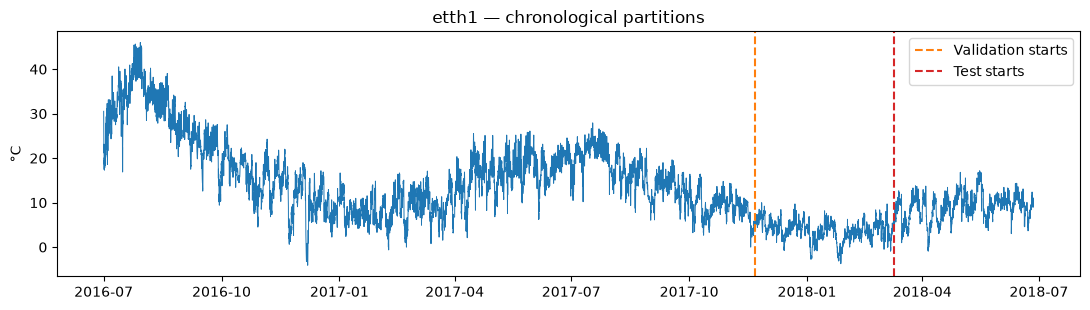

In [3]:
ETTH1_URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"
JENA_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
cache_dir = Path("benchmark_data")
cache_dir.mkdir(parents=True, exist_ok=True)

def get_dataset_file(name, url):
    path = cache_dir / name
    if not path.exists():
        print("Downloading public dataset:",url)
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as exc:
            raise RuntimeError(f"Could not download {name}. Download from {url} and save to {path} manually.") from exc
    return path

if DATASET == "co2":
    LOOKBACK, HORIZON, UNIT, TARGET = 156, 13, "ppm", "co2"
    frame = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(CO2_GZIP_BASE64))),parse_dates=["date"])
    frame = frame.set_index("date").asfreq("W-SAT")
    observed = frame[TARGET].notna().to_numpy()
    frame = frame.ffill()   # past-only imputation
elif DATASET == "etth1":
    LOOKBACK, HORIZON, UNIT, TARGET = 168, 24, "°C", "OT"
    csv_path = get_dataset_file("ETTh1.csv", ETTH1_URL)
    frame = pd.read_csv(csv_path,parse_dates=["date"]).set_index("date").asfreq("h")
    observed = frame[TARGET].notna().to_numpy()
    frame = frame.ffill()
elif DATASET == "jena":
    LOOKBACK, HORIZON, UNIT, TARGET = 168, 24, "°C", "T (degC)"
    zip_path = get_dataset_file("jena_climate_2009_2016.csv.zip", JENA_URL)
    with zipfile.ZipFile(zip_path) as archive:
        csv_name = next((name for name in archive.namelist() if name.endswith(".csv")),None)
        if not csv_name:raise ValueError("The Jena ZIP archive has no CSV file")
        with archive.open(csv_name) as fp:
            raw = pd.read_csv(fp)
    raw["date"] = pd.to_datetime(raw.pop("Date Time"),format="%d.%m.%Y %H:%M:%S")
    raw = raw.set_index("date").sort_index()
    # A controlled historical subset of weather variables. Never use future measured weather.
    # -9999 signifies invalid wind observations; replace with NaN BEFORE aggregating.
    for wind in ["wv (m/s)", "max. wv (m/s)"]:
        raw.loc[raw[wind] < 0,wind] = np.nan
    radians = np.deg2rad(raw["wd (deg)"].astype(float))
    raw["wind_dir_sin"] = np.sin(radians)
    raw["wind_dir_cos"] = np.cos(radians)
    columns = [TARGET,"p (mbar)","rh (%)","wv (m/s)","Tdew (degC)",
               "VPact (mbar)","rho (g/m**3)","wind_dir_sin","wind_dir_cos"]
    frame = raw[columns].resample("h").mean()   # strictly historical aggregation, hourly forecast steps
    observed = frame[TARGET].notna().to_numpy()
    frame = frame.ffill()  # causal gap fill; no backfill from future
else:
    raise ValueError("DATASET must be one of: co2, etth1, jena")
if frame.isna().any().any():
    raise ValueError("Leading missing values remain; cannot safely forward fill this dataset")
assert frame.index.is_monotonic_increasing and not frame.index.has_duplicates
assert np.isfinite(frame.to_numpy(dtype=float)).all()
N = len(frame)
train_end, val_end = int(.70*N), int(.85*N)
origin_sets = {
    "Train": np.arange(LOOKBACK,train_end-HORIZON+1),
    "Validation": np.arange(train_end,val_end-HORIZON+1),
    "Test": np.arange(val_end,N-HORIZON+1)
}
# Deterministic, evenly spaced subsampling of origins in large series.
# No sampling by target magnitude or forecast difficulty.
for part, max_n in (("Train",MAX_TRAIN_ORIGINS),("Validation",MAX_VAL_ORIGINS),("Test",MAX_TEST_ORIGINS)):
    origins=origin_sets[part]
    if len(origins)>max_n:
        origin_sets[part]=origins[np.linspace(0,len(origins)-1,max_n,dtype=int)]
assert all(len(v)>0 for v in origin_sets.values())
assert max(origin_sets["Train"])+HORIZON <= train_end
assert min(origin_sets["Validation"])>=train_end
assert max(origin_sets["Validation"])+HORIZON <= val_end
assert min(origin_sets["Test"])>=val_end
print(DATASET,"| rows",N,"| date range",frame.index[0],"to",frame.index[-1])
print("Target:",TARGET,"| historical sensors:",list(frame.columns.drop(TARGET)))
for part, orig in origin_sets.items():
    print(part,len(orig),"origins",frame.index[orig[0]],"to",frame.index[orig[-1]+HORIZON-1])
fig,ax=plt.subplots(figsize=(11,3.2))
ax.plot(frame.index,frame[TARGET],lw=.7)
ax.axvline(frame.index[train_end],color="tab:orange",linestyle="--",label="Validation starts")
ax.axvline(frame.index[val_end],color="tab:red",linestyle="--",label="Test starts")
ax.set(title=f"{DATASET} — chronological partitions",ylabel=UNIT)
ax.legend();plt.tight_layout();plt.show()


## Strictly causal features and target representation

All models start from the same `LOOKBACK` historical measurements, known-in-advance calendar, and identical chronological train / validation / test windows. The target is **relative to the last history value**, so even tree models can extrapolate levels. Every feature is computed **using only measurements strictly earlier than the forecast origin**. Feature scales are learned on the training-origin samples only.

We now create a separate, explicit **statistical-feature matrix**: selected lags, rolling means/std/min/max, trend slopes, season-over-season changes, matched seasonal historical values for the future horizon, and seasonal-drift summaries. On CO₂, the season is 52 weeks; on ETTh1, 24 hours (with optional 168-hour seasonal matches). These features provide **no new information** beyond the history the models already see.

By default this notebook benchmarks **CatBoost (relative)** (original flattened inputs) vs **CatBoost (engineered)** (exact original inputs *plus* statistics), while keeping the neural inputs unchanged so historical comparisons remain straightforward. Set `NEURAL_ENGINEERED_FEATURES=True` to provide the very same statistics to all neural networks, too. For careful architecture comparisons, consider both input regimes rather than giving the impression that only one model family can use feature engineering.

In [4]:
values=frame[TARGET].to_numpy(dtype=np.float64)
raw_measurements=frame.to_numpy(dtype=np.float64)
other_names=[c for c in frame.columns if c!=TARGET]

idx=frame.index
if DATASET=="co2":
    phase=(idx.dayofyear.to_numpy()-1)/np.where(idx.is_leap_year,366.,365.)
    calendar=np.column_stack([np.sin(2*np.pi*phase),np.cos(2*np.pi*phase)]).astype(np.float32)
    cal_names=["year_sin","year_cos"]
else:
    h=idx.hour.to_numpy();wd=idx.dayofweek.to_numpy()
    calendar=np.column_stack([np.sin(2*np.pi*h/24),np.cos(2*np.pi*h/24),
                              np.sin(2*np.pi*wd/7),np.cos(2*np.pi*wd/7),
                              np.sin(2*np.pi*idx.dayofyear.to_numpy()/365.25),
                              np.cos(2*np.pi*idx.dayofyear.to_numpy()/365.25)]).astype(np.float32)
    cal_names=["hour_sin","hour_cos","weekday_sin","weekday_cos","year_sin","year_cos"]
extra=frame[other_names].to_numpy(dtype=np.float64) if other_names else np.empty((N,0))
extra_mean=extra[:train_end].mean(axis=0) if other_names else np.empty(0)
extra_std=np.maximum(extra[:train_end].std(axis=0),1e-6) if other_names else np.empty(0)
extra_scaled=((extra-extra_mean)/extra_std).astype(np.float32)
# Delta magnitude / normalization fitted using training targets ONLY.
deltas=np.concatenate([values[t:t+HORIZON]-values[t-1] for t in origin_sets["Train"]])
delta_scale=float(deltas.std())
assert delta_scale > 1e-6
# Use a scale grounded in the train period even for the target's *historical* differences.
hist_scale=float(np.std(np.diff(values[:train_end])))
assert hist_scale>1e-6

PAST_DIM=1+len(other_names)+calendar.shape[1]
CONTEXT_DIM=HORIZON*calendar.shape[1]

def features_for_origins(origins):
    past=np.empty((len(origins),LOOKBACK,PAST_DIM),np.float32)
    context=np.empty((len(origins),CONTEXT_DIM),np.float32)
    target=np.empty((len(origins),HORIZON),np.float32)
    anchors=np.empty(len(origins),np.float64)
    for i,t in enumerate(origins):
        a=values[t-1]
        anchors[i]=a
        past[i,:,0]=((values[t-LOOKBACK:t]-a)/hist_scale).astype(np.float32)
        past[i,:,1:1+len(other_names)]=extra_scaled[t-LOOKBACK:t]
        past[i,:,1+len(other_names):]=calendar[t-LOOKBACK:t]
        context[i]=calendar[t:t+HORIZON].reshape(-1)
        target[i]=((values[t:t+HORIZON]-a)/delta_scale).astype(np.float32)
    return past,context,target,anchors

batches={k:features_for_origins(v) for k,v in origin_sets.items()}
for k,(x,c,y,a) in batches.items():
    print(k, 'history',x.shape,'future-known calendar',c.shape,'target',y.shape)
    assert np.isfinite(x).all() and np.isfinite(c).all() and np.isfinite(y).all()
assert PAST_DIM==1+len(other_names)+len(cal_names)
print('train-only hist_scale=',round(hist_scale,5),'delta_scale=',round(delta_scale,5))

# Leakage / reconstruction unit tests.
t=origin_sets['Test'][0]
x,c,y,a=features_for_origins(np.array([t]))
assert np.isclose(a[0],values[t-1])
assert np.allclose(y[0]*delta_scale+a[0],values[t:t+HORIZON],atol=1e-5)
assert not np.any(np.isnan(frame.to_numpy()))

Train history (8000, 168, 13) future-known calendar (8000, 144) target (8000, 24)
Validation history (1600, 168, 13) future-known calendar (1600, 144) target (1600, 24)
Test history (1600, 168, 13) future-known calendar (1600, 144) target (1600, 24)
train-only hist_scale= 1.01807 delta_scale= 2.8681


## Engineered statistical features — no future leakage

The source is the same past window already available to the neural nets. Target-derived features are expressed as **differences from the final historical observation**, divided by a training-only scale (preventing absolute CO₂ level extrapolation from becoming the bottleneck). We compute:

- Selected recent and seasonal **lags** (weekly CO₂: 1, 4, 13, 26, 52, 104 weeks; hourly ETT: 1, 3, 24, 48, 72, 168 hours).
- **Rolling mean, standard deviation, min/max, and end-minus-start** for several windows.
- **Linear slopes** of recent 13/26/52-week windows (or hourly analogues).
- **Seasonal differences**, year-over-year change and trailing-year seasonal drift for CO₂; recent-day/week matches for ETT.
- Entire **same-season prior path** corresponding to each of the next 13 or 24 forecast steps. This is available at prediction time (e.g., CO₂ next-week forecast aligns with a measured week in the *past* year).

`engineered_feature_names` labels all columns. `engineered_by_part` contains train-only standardized copies. The leakage check below deliberately replaces all future measurements with absurd values and verifies that the derived features do not change.


In [5]:
# Engineer deterministic features *only* from past observations. Never read series[t:] here.
SEASONAL_PERIODS = [52] if DATASET == 'co2' else [24, 168]
LAG_SET = [1, 4, 13, 26, 52, 104] if DATASET == 'co2' else [1, 3, 24, 48, 72, 168]
ROLL_WINDOWS = [4, 13, 26, 52, 104] if DATASET == 'co2' else [6, 24, 48, 72, 168]
SLOPE_WINDOWS = [13, 26, 52, 104] if DATASET == 'co2' else [24, 48, 72, 168]

# Precomputed slope coefficients avoid repeated polynomial fits (and define exact units).
slope_weights = {}
for window in SLOPE_WINDOWS:
    if window <= LOOKBACK:
        x = np.arange(window, dtype=np.float64)
        x -= x.mean()
        slope_weights[window] = x / (x @ x)

def engineered_features_at(t, series=values):
    """Return an ordered mapping of features visible strictly before forecast origin t."""
    past = np.asarray(series[t-LOOKBACK:t], dtype=np.float64)
    assert len(past) == LOOKBACK
    anchor = past[-1]
    z = (past - anchor) / hist_scale
    f = {}
    for lag in LAG_SET:
        if lag <= LOOKBACK:
            f[f'lag_{lag}_relative'] = float(z[-lag])
    for w in ROLL_WINDOWS:
        if w <= LOOKBACK:
            a = z[-w:]
            f[f'rolling_mean_{w}'] = float(np.mean(a))
            f[f'rolling_std_{w}'] = float(np.std(a))
            f[f'rolling_min_{w}'] = float(np.min(a))
            f[f'rolling_max_{w}'] = float(np.max(a))
            f[f'rolling_change_{w}'] = float(a[-1]-a[0])
    for w, weights in slope_weights.items():
        f[f'trend_slope_{w}'] = float(weights @ z[-w:])
    for p in SEASONAL_PERIODS:
        if p <= LOOKBACK:
            # Last observed week / hour compared to the same season one cycle ago.
            # For p==LOOKBACK, a previous-cycle match of the last point is unavailable.
            for h in range(min(HORIZON,p)):
                f[f'season_{p}_future_step_{h+1}'] = float(z[-p+h])
        if 2*p <= LOOKBACK:
            d = z[-p:] - z[-2*p:-p]
            f[f'seasonal_diff_mean_{p}'] = float(np.mean(d))
            f[f'seasonal_diff_std_{p}'] = float(np.std(d))
            f[f'seasonal_diff_latest_{p}'] = float(d[-1])
            # The observed previous cycle + historical cycle drift for each step.
            for h in range(min(HORIZON,p)):
                f[f'season_{p}_drift_adjusted_step_{h+1}'] = float(z[-p+h]+np.mean(d))
    # ETT additionally has six historical sensors. Aggregate *past-only* values for them.
    for j, feature_name in enumerate(other_names):
        past_sensor = np.asarray(extra_scaled[t-LOOKBACK:t,j],dtype=np.float64)
        for w in (24,72):
            if w <= LOOKBACK:
                a = past_sensor[-w:]
                f[f'{feature_name}_mean_{w}'] = float(a.mean())
                f[f'{feature_name}_std_{w}'] = float(a.std())
                f[f'{feature_name}_slope_{w}'] = float(slope_weights.get(w, np.zeros(w)) @ a) if w in slope_weights else float((a[-1]-a[0])/(w-1))
    return f

engineered_feature_names = list(engineered_features_at(origin_sets['Train'][0]).keys())
raw_engineered_by_part = {}
for part, origins in origin_sets.items():
    arr = np.asarray([list(engineered_features_at(t).values()) for t in origins], dtype=np.float64)
    assert arr.shape == (len(origins), len(engineered_feature_names)) and np.isfinite(arr).all()
    raw_engineered_by_part[part] = arr

# Standardize using *only training origins*. Other partitions are untouched by fit.
eng_mean = raw_engineered_by_part['Train'].mean(axis=0)
eng_std = raw_engineered_by_part['Train'].std(axis=0)
eng_std = np.where(eng_std < 1e-6, 1.0, eng_std)
engineered_by_part = {k: ((arr-eng_mean)/eng_std).astype(np.float32)
                      for k,arr in raw_engineered_by_part.items()}
assert all(np.isfinite(a).all() for a in engineered_by_part.values())

# Strong causality test: tampering with the *entire* future can never change features.
t = int(origin_sets['Test'][0])
tampered = values.copy()
tampered[t:] += 10000.0
old_features = np.array(list(engineered_features_at(t,values).values()))
new_features = np.array(list(engineered_features_at(t,tampered).values()))
assert np.array_equal(old_features,new_features), 'Future data leaked into engineered features!'

# Preserve raw covariates separately so raw-lag CatBoost NEVER accidentally sees engineered inputs.
raw_calendar_by_part = {k: c.copy() for k, (_,c,_,_) in batches.items()}
RAW_CONTEXT_DIM=CONTEXT_DIM
if NEURAL_ENGINEERED_FEATURES:
    batches = {k: (x, np.concatenate([c, engineered_by_part[k]],axis=1),y,a)
               for k,(x,c,y,a) in batches.items()}
    CONTEXT_DIM = RAW_CONTEXT_DIM + len(engineered_feature_names)
print('Engineered feature count:',len(engineered_feature_names))
print('Example names:',engineered_feature_names[:12])
print('Neural inputs:', 'raw + engineered' if NEURAL_ENGINEERED_FEATURES else 'raw only')
print('Causality and finite-value checks passed')


Engineered feature count: 146
Example names: ['lag_1_relative', 'lag_3_relative', 'lag_24_relative', 'lag_48_relative', 'lag_72_relative', 'lag_168_relative', 'rolling_mean_6', 'rolling_std_6', 'rolling_min_6', 'rolling_max_6', 'rolling_change_6', 'rolling_mean_24']
Neural inputs: raw only
Causality and finite-value checks passed


In [6]:
class WindowDataset(TorchDataset):
    def __init__(self, part):
        self.x,self.c,self.y,_=batches[part]
    def __len__(self):return len(self.x)
    def __getitem__(self,i):return (torch.from_numpy(self.x[i]),torch.from_numpy(self.c[i]),torch.from_numpy(self.y[i]))
def loader(part, shuffle=False):
    return DataLoader(WindowDataset(part),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

Xtr,Ctr,Ytr,Atr=batches['Train'];Xva,Cva,Yva,Ava=batches['Validation']
Xte,Cte,Yte,Ate=batches['Test']
Yte_raw=Yte.astype(np.float64)*delta_scale+Ate[:,None]
observed_test=np.stack([observed[t:t+HORIZON] for t in origin_sets['Test']])

def evaluate(pred_raw):
    pred_raw=np.asarray(pred_raw,dtype=float)
    err=pred_raw-Yte_raw
    assert err.shape==Yte_raw.shape and np.isfinite(err).all()
    return dict(rmse=float(np.sqrt(np.mean(err**2))),mae=float(np.mean(np.abs(err))),
                observed_rmse=float(np.sqrt(np.mean(err[observed_test]**2))))

def to_raw(pred_scaled,anchors): return np.asarray(pred_scaled,dtype=np.float64)*delta_scale+anchors[:,None]

## Reference baselines

The *last observation* is difficult to beat for short horizons. For weekly CO₂ we additionally include a prior-year seasonal forecast with a trailing-year annual drift estimate; it is strictly causal at each origin. These baselines require no training.

In [7]:
naive_last=np.repeat(Ate[:,None],HORIZON,axis=1)
baseline_rows=[dict(model='Last observed',family='Naive',**evaluate(naive_last))]
all_pred={'Last observed':naive_last}
if DATASET=='co2':
    # 52 weeks approximates 1 year; the drift estimate compares the prior two annual windows.
    seasonal=[]
    for t in origin_sets['Test']:
        past_year=values[t-52:t]
        older_year=values[t-104:t-52]
        drift=float(np.mean(past_year-older_year))
        seasonal.append(values[t-52:t-52+HORIZON]+drift)
    seasonal=np.asarray(seasonal)
    all_pred['Prior-year + drift']=seasonal
    baseline_rows.append(dict(model='Prior-year + drift',family='Naive',**evaluate(seasonal)))
display(pd.DataFrame(baseline_rows).round(4))

,model,family,rmse,mae,observed_rmse
0,Last observed,Naive,1.9897,1.4568,1.9897


## The architectures

The nine available architectures are derived from the original electricity notebook: Linear, MLP, CNN1D, GRU, LSTM, TCN, N-BEATS-style, Patch Transformer, and Transformer. **The default quick run trains five**; set `RUN_ALL_MODELS = True` above to run all nine. The TCN now has dilations to cover at least 156/168 past steps. `Patch Transformer` is a lightweight patch-token Transformer, **not** a claim of a full official PatchTST implementation. N-BEATS-style similarly denotes a small residual-block implementation, not the original paper's exact training recipe.

In [8]:
class LinearForecast(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Linear(LOOKBACK*PAST_DIM+CONTEXT_DIM,HORIZON)
    def forward(self,x,c):return self.net(torch.cat([x.flatten(1),c],dim=1))

class MLPForecast(nn.Module):
    def __init__(self):
        super().__init__();d=LOOKBACK*PAST_DIM+CONTEXT_DIM
        self.net=nn.Sequential(nn.Linear(d,256),nn.ReLU(),nn.Dropout(.1),nn.Linear(256,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x,c):return self.net(torch.cat([x.flatten(1),c],dim=1))

class CNNForecast(nn.Module):
    def __init__(self):
        super().__init__();self.conv=nn.Sequential(nn.Conv1d(PAST_DIM,32,5,padding=2),nn.ReLU(),nn.Conv1d(32,64,5,padding=2),nn.ReLU(),nn.AdaptiveAvgPool1d(1))
        self.head=nn.Linear(64+CONTEXT_DIM,HORIZON)
    def forward(self,x,c):return self.head(torch.cat([self.conv(x.transpose(1,2)).squeeze(-1),c],axis=1))

class CausalConv(nn.Module):
    def __init__(self,inc,outc,k,d):
        super().__init__();self.pad=(k-1)*d;self.conv=nn.Conv1d(inc,outc,k,dilation=d)
    def forward(self,x):return self.conv(F.pad(x,(self.pad,0)))

class TCNForecast(nn.Module):
    def __init__(self):
        super().__init__();layers=[];d=PAST_DIM
        self.dilations=(1,2,4,8,16,32,64)
        for dilation in self.dilations:
            layers += [CausalConv(d,32,3,dilation),nn.ReLU()];d=32
        self.conv=nn.Sequential(*layers);self.head=nn.Linear(32+CONTEXT_DIM,HORIZON)
        self.receptive_field=1+2*sum(self.dilations)
    def forward(self,x,c):return self.head(torch.cat([self.conv(x.transpose(1,2))[:,:,-1],c],axis=1))

class RNNForecast(nn.Module):
    def __init__(self,kind):
        super().__init__();self.rnn=(nn.GRU if kind=='GRU' else nn.LSTM)(PAST_DIM,48,batch_first=True)
        self.head=nn.Linear(48+CONTEXT_DIM,HORIZON)
    def forward(self,x,c):
        o,_=self.rnn(x);return self.head(torch.cat([o[:,-1],c],dim=1))

class TokenTransformer(nn.Module):
    def __init__(self,patch_size):
        super().__init__();self.patch_size=patch_size
        self.npatches=math.ceil(LOOKBACK/patch_size)
        self.project=nn.Linear(patch_size*PAST_DIM,48)
        self.position=nn.Parameter(torch.randn(1,self.npatches,48)*.02)
        lyr=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,dropout=.1,batch_first=True,norm_first=True)
        self.enc=nn.TransformerEncoder(lyr,num_layers=2,enable_nested_tensor=False)
        self.head=nn.Linear(48+CONTEXT_DIM,HORIZON)
    def forward(self,x,c):
        pad=self.npatches*self.patch_size-LOOKBACK
        if pad:x=F.pad(x.transpose(1,2),(pad,0)).transpose(1,2)
        x=x.reshape(x.shape[0],self.npatches,-1)
        tokens=self.enc(self.project(x)+self.position).mean(dim=1)
        return self.head(torch.cat([tokens,c],dim=1))

class NBeatsBlock(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(LOOKBACK*PAST_DIM+CONTEXT_DIM,192),nn.ReLU(),nn.Linear(192,192),nn.ReLU())
        self.back=nn.Linear(192,LOOKBACK*PAST_DIM);self.fore=nn.Linear(192,HORIZON)
    def forward(self,x,c):
        hidden=self.net(torch.cat([x,c],dim=1));return self.back(hidden),self.fore(hidden)

class NBeatsForecast(nn.Module):
    def __init__(self):super().__init__();self.blocks=nn.ModuleList([NBeatsBlock() for _ in range(3)])
    def forward(self,x,c):
        residual=x.flatten(1);prediction=x.new_zeros((len(x),HORIZON))
        for block in self.blocks:
            back,fore=block(residual,c);residual=residual-back;prediction=prediction+fore
        return prediction

MODEL_FACTORIES={'Linear':LinearForecast,'MLP':MLPForecast,'CNN1D':CNNForecast,
    'GRU':lambda:RNNForecast('GRU'),'LSTM':lambda:RNNForecast('LSTM'),
    'TCN':TCNForecast,'N-BEATS-style':NBeatsForecast,
    'Patch Transformer':lambda:TokenTransformer(12),
    'Transformer':lambda:TokenTransformer(1)}
assert TCNForecast().receptive_field>=LOOKBACK
for name in MODELS:
    model=MODEL_FACTORIES[name]()
    with torch.no_grad():
        y=model(torch.from_numpy(Xtr[:2]),torch.from_numpy(Ctr[:2]))
    assert y.shape==(2,HORIZON)
print('Shape checks OK for',len(MODELS),'models')

Shape checks OK for 8 models


## Training and validation

Neural networks use the same AdamW/early-stopping budget and normalized relative targets as before. By default they still use the raw lags; `NEURAL_ENGINEERED_FEATURES=True` appends exactly the same additional statistics to their context input. CatBoost is trained with `MultiRMSE` on the identical training/validation origins and relative target representation. Its **original flattened inputs** are compared against **the original inputs plus explicit statistical features** using identical tree depth, iteration budget, and early stopping. Only the feature representation differs.

In [9]:
@torch.no_grad()
def predict_neural(model,part):
    model.eval(); chunks=[]
    for x,c,_ in loader(part): chunks.append(model(x.to(DEVICE),c.to(DEVICE)).cpu().numpy())
    return np.concatenate(chunks,axis=0)

def train_neural(name):
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    model=MODEL_FACTORIES[name]().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-4)
    best=float('inf');best_ep=None;best_state=None;stale=0;hist=[]
    for epoch in range(1,MAX_EPOCHS+1):
        model.train(); train_sum=ntrain=0
        for x,c,y in loader('Train',True):
            x=x.to(DEVICE);c=c.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            output=model(x,c);loss=F.mse_loss(output,y)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step()
            train_sum+=loss.item()*y.numel();ntrain+=y.numel()
        model.eval(); losses=[]; weights=[]
        with torch.no_grad():
            for x,c,y in loader('Validation'):
                val_loss=F.mse_loss(model(x.to(DEVICE),c.to(DEVICE)),y.to(DEVICE),reduction='sum').item()
                losses.append(val_loss);weights.append(y.numel())
        valid=sum(losses)/sum(weights)
        hist.append({'epoch':epoch,'train_mse_scaled':train_sum/ntrain,'val_mse_scaled':valid})
        if valid < best-1e-6:
            best=valid;best_ep=epoch;best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};stale=0
        else:
            stale+=1
            if stale>=PATIENCE:break
    model.load_state_dict(best_state)
    pred=to_raw(predict_neural(model,'Test'),Ate)
    valpred=to_raw(predict_neural(model,'Validation'),Ava)
    valtrue=to_raw(Yva,Ava)
    row={'model':name,'family':'Neural','best_epoch':best_ep,'epochs_run':len(hist),
         'parameters':sum(p.numel() for p in model.parameters()),
         'val_rmse':float(np.sqrt(np.mean((valpred-valtrue)**2))),**evaluate(pred)}
    return row,pred,pd.DataFrame(hist)

output_dir=Path('forecast_challenge_outputs')/DATASET
output_dir.mkdir(parents=True,exist_ok=True)
results=list(baseline_rows)
for name in MODELS:
    start=time.perf_counter()
    row,pred,history=train_neural(name)
    all_pred[name]=pred;results.append(row)
    history.to_csv(output_dir/(name.replace(' ','_')+'_history.csv'),index=False)
    print(f'{name:18s} val={row["val_rmse"]:.4f} test={row["rmse"]:.4f} {UNIT} | {time.perf_counter()-start:.1f}s | epoch={row["best_epoch"]}',flush=True)

Linear             val=1.7107 test=2.0571 °C | 2.5s | epoch=3
MLP                val=1.6640 test=1.9983 °C | 2.5s | epoch=1
CNN1D              val=1.6026 test=2.0460 °C | 7.3s | epoch=13
GRU                val=1.7011 test=1.9072 °C | 28.8s | epoch=4
LSTM               val=1.6732 test=1.8866 °C | 5.8s | epoch=3
TCN                val=1.6859 test=1.9855 °C | 4.4s | epoch=8
N-BEATS-style      val=1.6500 test=1.9863 °C | 4.8s | epoch=1
Patch Transformer  val=1.7364 test=1.8861 °C | 4.5s | epoch=1


In [10]:
from catboost import CatBoostRegressor

def flat(x,c):
    return np.concatenate((x.reshape(len(x),-1),c),axis=1).astype(np.float32)

# Raw CatBoost always uses raw historical sequences and raw calendar,
# even when NEURAL_ENGINEERED_FEATURES=True.
Ftr=flat(Xtr,raw_calendar_by_part['Train'])
Fva=flat(Xva,raw_calendar_by_part['Validation'])
Fte=flat(Xte,raw_calendar_by_part['Test'])
Ftr_eng=np.concatenate([Ftr,engineered_by_part['Train']],axis=1)
Fva_eng=np.concatenate([Fva,engineered_by_part['Validation']],axis=1)
Fte_eng=np.concatenate([Fte,engineered_by_part['Test']],axis=1)
assert Ftr_eng.shape[1]==Ftr.shape[1]+len(engineered_feature_names)

# Both relative configurations have identical targets, split, and CatBoost hyperparameters.
# This makes the engineered-vs-raw comparison an ablation, not an architectural claim.
def fit_catboost(relative=True, engineered=False):
    if not relative and engineered:
        raise ValueError('Only the relative-target configuration has an engineered ablation')
    name = ('CatBoost (engineered)' if engineered else
            'CatBoost (relative)' if relative else 'CatBoost (raw level)')
    ty = Ytr if relative else to_raw(Ytr,Atr)
    vy = Yva if relative else to_raw(Yva,Ava)
    tr,va,te = (Ftr_eng,Fva_eng,Fte_eng) if engineered else (Ftr,Fva,Fte)
    model = CatBoostRegressor(iterations=CATBOOST_ITERATIONS,depth=6,learning_rate=.05,
        loss_function='MultiRMSE',l2_leaf_reg=3,random_seed=SEED,thread_count=4,
        task_type='CPU',allow_writing_files=False)
    start=time.perf_counter()
    model.fit(tr,ty,eval_set=(va,vy),early_stopping_rounds=CATBOOST_PATIENCE,
              use_best_model=True,verbose=False)
    test_raw = to_raw(model.predict(te),Ate) if relative else model.predict(te)
    valid_raw = to_raw(model.predict(va),Ava) if relative else model.predict(va)
    row = {'model':name,'family':'Tree','best_epoch':int(model.get_best_iteration()+1),
           'epochs_run':model.tree_count_,'parameters':np.nan,
           'feature_count':tr.shape[1],
           'val_rmse':float(np.sqrt(np.mean((valid_raw-to_raw(Yva,Ava))**2))),
           **evaluate(test_raw)}
    print(f'{name:24s} val={row["val_rmse"]:.4f} test={row["rmse"]:.4f} {UNIT} '
          f'| {time.perf_counter()-start:.1f}s | trees={model.tree_count_}',flush=True)
    return row,test_raw,model

catboost_models={}
for relative, engineered in ([(True,False)]
                             + ([(True,True)] if RUN_ENGINEERED_CATBOOST else [])
                             + ([(False,False)] if RUN_RAW_CATBOOST else [])):
    row,pred,model=fit_catboost(relative=relative, engineered=engineered)
    results.append(row)
    all_pred[row['model']]=pred
    catboost_models[row['model']]=model

if RUN_ENGINEERED_CATBOOST:
    # Built-in importance is for display/diagnostics, not selecting inputs using test outcomes.
    feature_importance=catboost_models['CatBoost (engineered)'].get_feature_importance()
    name_list=[f'raw_input_{i}' for i in range(Ftr.shape[1])]+engineered_feature_names
    importance_df=pd.DataFrame({'feature':name_list,'importance':feature_importance})
    engineered_importance=importance_df.iloc[Ftr.shape[1]:].sort_values('importance',ascending=False)
    print('\nTop engineered features by CatBoost importance:')
    display(engineered_importance.head(12).round(3))


CatBoost (relative)      val=1.5509 test=1.7221 °C | 107.5s | trees=22
CatBoost (engineered)    val=1.5458 test=1.7192 °C | 140.7s | trees=20

Top engineered features by CatBoost importance:


,feature,importance
2357,rolling_max_168,2.548
2425,season_168_future_step_12,2.164
2354,rolling_mean_168,2.105
2424,season_168_future_step_11,1.228
2421,season_168_future_step_8,0.997
2427,season_168_future_step_14,0.993
2377,season_24_future_step_15,0.702
2376,season_24_future_step_14,0.697
2350,rolling_std_72,0.679
2378,season_24_future_step_16,0.635


## Results: held-out RMSE and diagnostic plots

**CatBoost (relative)** is the original raw-lag baseline, **CatBoost (engineered)** uses additional causal statistical summaries of the *same* past history. Both use the same relative target and identical tree budget. The **CatBoost (raw level)** variant is only an optional target ablation. `NEURAL_ENGINEERED_FEATURES` controls whether the neural models get these summaries as auxiliary inputs. Do not pick models or feature sets by repeatedly inspecting this test-set ranking; decide via validation and confirm on a new chronological fold.

,model,family,rmse,mae,observed_rmse,val_rmse,best_epoch
0,CatBoost (engineered),Tree,1.7192,1.2364,1.7192,1.5458,20.0
1,CatBoost (relative),Tree,1.7221,1.2395,1.7221,1.5509,22.0
2,Patch Transformer,Neural,1.8861,1.4112,1.8861,1.7364,1.0
3,LSTM,Neural,1.8866,1.3838,1.8866,1.6732,3.0
4,GRU,Neural,1.9072,1.4298,1.9072,1.7011,4.0
5,TCN,Neural,1.9855,1.4651,1.9855,1.6859,8.0
6,N-BEATS-style,Neural,1.9863,1.4518,1.9863,1.6500,1.0
7,Last observed,Naive,1.9897,1.4568,1.9897,NaN,NaN
8,MLP,Neural,1.9983,1.4849,1.9983,1.6640,1.0
9,CNN1D,Neural,2.0460,1.4998,2.0460,1.6026,13.0


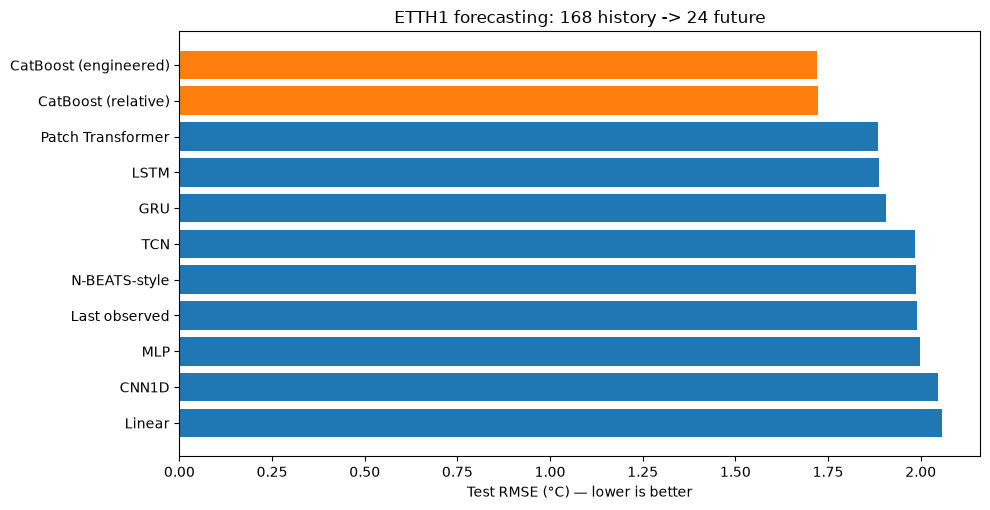

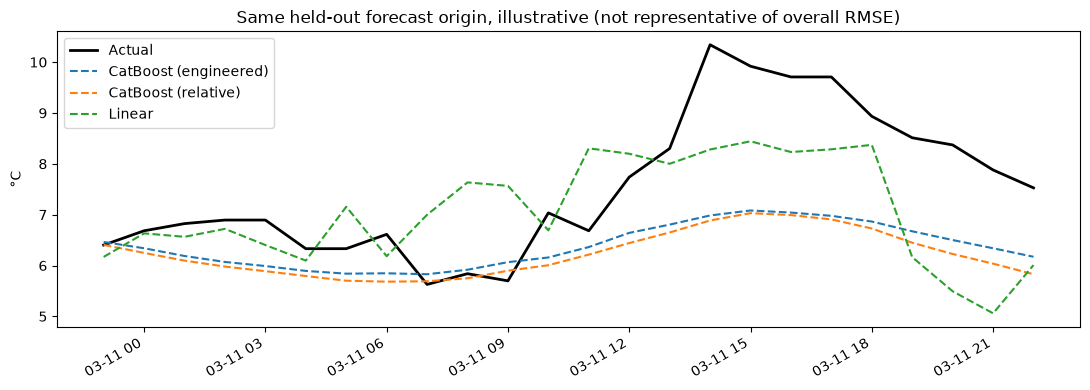

Best neural: Patch Transformer 1.8861 °C
CatBoost (relative, raw lags): 1.7221 °C
CatBoost (engineered): 1.7192 °C
Engineered - raw CatBoost VALIDATION RMSE: -0.0051 °C
Engineered - raw CatBoost TEST RMSE: -0.0029 °C
Neural vs strongest tested relative-target CatBoost (CatBoost (engineered)): +9.7% in test RMSE (negative means neural wins)

Validation-selected winner: CatBoost (engineered) | validation RMSE: 1.5458 | test RMSE: 1.7192
Test ranking is descriptive; repeated test-driven model or dataset selection overfits the test set.
Outputs: /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/etth1


In [11]:
result_df=pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
display(result_df[['model','family','rmse','mae','observed_rmse','val_rmse','best_epoch']].round(4))
result_df.to_csv(output_dir/'comparison.csv',index=False)
np.savez_compressed(output_dir/'predictions.npz',actual=Yte_raw,origins=origin_sets['Test'],
                    **{name.replace(' ','_').replace('(','').replace(')',''):pred for name,pred in all_pred.items()})
fig,ax=plt.subplots(figsize=(10,5.2))
ranked=result_df.iloc[::-1]
ax.barh(ranked['model'],ranked['rmse'],color=['tab:orange' if m.startswith('CatBoost') else 'tab:blue' for m in ranked['model']])
ax.set(xlabel=f'Test RMSE ({UNIT}) — lower is better',title=f'{DATASET.upper()} forecasting: {LOOKBACK} history -> {HORIZON} future')
fig.tight_layout();fig.savefig(output_dir/'rmse_ranking.png',dpi=140);plt.show()

# A fixed part of the test period, not a cherry-picked error example.
start_i=min(15,len(origin_sets['Test'])-1)
figure,axis=plt.subplots(figsize=(11,4))
dates=frame.index[origin_sets['Test'][start_i]:origin_sets['Test'][start_i]+HORIZON]
axis.plot(dates,Yte_raw[start_i],color='black',linewidth=2,label='Actual')
for name in [result_df.iloc[0]['model'],'CatBoost (relative)','Linear']:
    if name in all_pred:axis.plot(dates,all_pred[name][start_i],linestyle='--',label=name)
axis.set(title='Same held-out forecast origin, illustrative (not representative of overall RMSE)',ylabel=UNIT)
axis.legend();figure.autofmt_xdate();figure.tight_layout();plt.show()

cat_rmse=next(r['rmse'] for r in results if r['model']=='CatBoost (relative)')
neural=sorted([r for r in results if r['family']=='Neural'],key=lambda r:r['rmse'])
print('Best neural:',neural[0]['model'],f'{neural[0]["rmse"]:.4f}',UNIT)
print('CatBoost (relative, raw lags):',f'{cat_rmse:.4f}',UNIT)
if RUN_ENGINEERED_CATBOOST:
    cat_eng_rmse=next(r['rmse'] for r in results if r['model']=='CatBoost (engineered)')
    cat_raw_val=next(r['val_rmse'] for r in results if r['model']=='CatBoost (relative)')
    cat_eng_val=next(r['val_rmse'] for r in results if r['model']=='CatBoost (engineered)')
    print('CatBoost (engineered):',f'{cat_eng_rmse:.4f}',UNIT)
    print('Engineered - raw CatBoost VALIDATION RMSE:',f'{cat_eng_val-cat_raw_val:+.4f}',UNIT)
    print('Engineered - raw CatBoost TEST RMSE:',f'{cat_eng_rmse-cat_rmse:+.4f}',UNIT)
best_cat_row = min((r for r in results if r['family']=='Tree' and r['model']!='CatBoost (raw level)'),key=lambda r:r['rmse'])
print('Neural vs strongest tested relative-target CatBoost ('+best_cat_row['model']+'):',
      f'{100*(neural[0]["rmse"]/best_cat_row["rmse"]-1):+.1f}% in test RMSE (negative means neural wins)')

# Save config/data provenance alongside outputs. Never report old results as current reruns.
run_info = {
    'dataset':DATASET,'target':TARGET,'unit':UNIT,'lookback':LOOKBACK,'horizon':HORIZON,
    'seed':SEED,'max_epochs':MAX_EPOCHS,'patience':PATIENCE,'catboost_iterations':CATBOOST_ITERATIONS,
    'catboost_patience':CATBOOST_PATIENCE,'neural_models':MODELS,
    'engineered_catboost':RUN_ENGINEERED_CATBOOST,'neural_engineered_features':NEURAL_ENGINEERED_FEATURES,
    'train_origins':len(origin_sets['Train']),'val_origins':len(origin_sets['Validation']),
    'test_origins':len(origin_sets['Test']),
    'data_start':str(frame.index[0]),'data_end':str(frame.index[-1]),
    'train_end':str(frame.index[train_end]),'validation_end':str(frame.index[val_end]),
    'source_url':{'co2':'statsmodels.datasets.co2.load_pandas()', 'etth1':ETTH1_URL,'jena':JENA_URL}[DATASET],
    'notes':'Single chronological split and seed. No tuning on held-out test. All models share same forecast origins.'
}
(output_dir/'run_info.json').write_text(json.dumps(run_info,indent=2),encoding='utf-8')
# Which model would have been chosen WITHOUT looking at test?
model_table=result_df.query("family != 'Naive'").sort_values('val_rmse')
print('\nValidation-selected winner:',model_table.iloc[0]['model'],
      '| validation RMSE:',round(model_table.iloc[0]['val_rmse'],4),
      '| test RMSE:',round(model_table.iloc[0]['rmse'],4))
print('Test ranking is descriptive; repeated test-driven model or dataset selection overfits the test set.')
print('Outputs:', output_dir.resolve())


## How to interpret this run

- Lower **test** RMSE means better performance on this one held-out period, not a universal winner.
- Use **validation** to choose models/settings; show the test scores once. Repeating experiments to select the most favorable test dataset biases the story.
- The CatBoost *engineered* model receives extra causal statistical features; this is an explicitly different feature budget. Its score cannot be claimed to isolate the architecture's effect.
- If you plan a Medium post, report configurations, datasets, split boundaries, training budget, and each source notebook. Share the generated CSV and code.
- Next steps for stronger claims: multiple seeds, rolling-origin periods, tuning-budget parity, a neural engineered-feature ablation, and block confidence intervals.